# **Predicting Students' Dropout and Academic Success**
**Team / Authors:** RxPulseMH — Deocampo, Jan Adrian | Jalbuena, Jerica Thea | Julabar, Jay Adrian | Maravilla, Louiena Paula | Brendia, Ricky Boy  
**Course:** ICT 110  
**Date:** November 15, 2026  

**Result Summary:** This study frames student retention at the Polytechnic Institute of Portalegre as a supervised binary classification task (`Dropout` vs. `Graduate`) across 3,630 student records and 36 demographic, socioeconomic, and two-semester academic features evaluated using the **$F_2$-Score** (which weights `Dropout` Recall twice as heavily as Precision). Across 5-fold stratified cross-validation on the 2,904-student training set, **Logistic Regression** achieves the highest performance with an **$F_2$-Score of 0.8619 ± 0.0105** (91.43% accuracy, 84.70% Dropout Recall), substantially outperforming Random Forest (**0.8403 ± 0.0176** $F_2$-Score), KNN (**0.7144 ± 0.0178** $F_2$-Score), and the naive majority-class baseline (**0.0000 $F_2$-Score**, 60.85% accuracy).

---
# **A. Problem Definition**

### **Brief Description**
This project utilizes the **Predict Students' Dropout and Academic Success** dataset from the UCI Machine Learning Repository (Dataset ID: 697), collected from the Polytechnic Institute of Portalegre in Portugal across academic years 2008/2009 to 2018/2019. The dataset integrates demographic, socioeconomic, macroeconomic, admission, and first- and second-semester academic performance records across 36 predictor attributes under the Creative Commons Attribution 4.0 International (CC BY 4.0) license.

### **Problem Statement (A1)**
Student attrition reduces graduation rates and institutional effectiveness. Identifying at-risk students enables academic administrators and advisers to deliver timely, targeted retention support. This project utilizes **supervised binary classification** to predict whether a student will ultimately graduate or drop out. By leveraging a comprehensive timeline of demographic, socioeconomic, and academic performance features across two semesters, the model aims to accurately classify eventual academic outcomes and assist in the university's retention efforts.

### **Guiding Questions (Stage A)**
* **A2 — Problem Framing:** This study is framed as **supervised binary classification**. Because historical student records are labeled with known academic outcomes and the operational goal is to categorize students into one of two discrete, mutually exclusive final states (`Dropout` or `Graduate`), binary classification directly fits the decision-support objective.
* **A3 — Target Variable and Measurement:** The outcome of interest is the `Target` variable, which records each student's definitive academic status (`Graduate`: 2,209 students, `Dropout`: 1,421 students) measured by the institution at the end of the normal duration of their course.
* **A4 — Evaluation Metric and Cost of Errors:** Success is defined by the **$F_2$-Score (`beta = 2`)** focused on the `Dropout` class. In an academic advising context, the real-world cost of prediction errors is asymmetric: a **False Negative** (failing to identify an actual `Dropout`) carries a high institutional cost because an at-risk student misses timely intervention and leaves the university, whereas a **False Positive** (incorrectly flagging a `Graduate` as at-risk) carries a low administrative cost (an adviser sending a routine check-in email). The $F_2$-score matches this reality by weighting **Recall** (catching actual dropouts) **twice as heavily** as **Precision** (avoiding false alarms), while still penalizing models that trigger excessive false alarms.
* **A7 — Naive Baseline Score:** A naive majority-class baseline (`DummyClassifier(strategy='most_frequent')`) that predicts `Graduate` for every student achieves **60.85% accuracy** (`0.6085`), which looks deceptively passable on the surface, but achieves a **0.0000 $F_2$-Score** because it catches 0% of actual dropouts (`0.0000` Recall and `0.0000` Precision on `Dropout`). Candidate machine learning models must substantially outperform this `0.0000` $F_2$-score floor.

### **1. Packages and Random Seeds**
We install the UCI repository helper library, import all required data manipulation, visualization, and machine learning packages, define our primary **$F_2$-Score** evaluation metric (`beta = 2`, positive label = `'Dropout'`), and lock the global random seed (`SEED = 42`).

In [ ]:
!pip install -q ucimlrepo

import random
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display
from ucimlrepo import fetch_ucirepo
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, fbeta_score, make_scorer, classification_report, confusion_matrix

# Set global random seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Define primary metric: F2-Score for the 'Dropout' class (weights Recall 2x higher than Precision)
f2_scorer = make_scorer(fbeta_score, beta=2, pos_label='Dropout', zero_division=0)

config_df = pd.DataFrame({
    'Configuration Item': ['Global Random Seed (SEED)', 'Problem Framing', 'Primary Evaluation Metric', 'Positive Target Class'],
    'Setting / Value': [str(SEED), 'Supervised Binary Classification', 'F2-Score (beta = 2, Recall weighted 2x)', 'Dropout']
})
display(config_df)

,Configuration Item,Setting / Value
0,Global Random Seed (SEED),42
1,Problem Framing,Supervised Binary Classification
2,Primary Evaluation Metric,"F2-Score (beta = 2, Recall weighted 2x)"
3,Positive Target Class,Dropout


**Output Interpretation:** All required libraries and the custom `f2_scorer` (`beta = 2` for `Dropout`) are initialized with the global random seed locked at `42`.

### **2. Dataset Loading and Scope Inspection (A3)**
We fetch the dataset (ID: 697) from the UCI Machine Learning Repository, scope the dataset to our binary target outcomes (`Graduate` and `Dropout`), and display the dataset dimensions and class distribution as clean tables.

In [ ]:
# Load dataset from UCI ML Repository (ID: 697)
uci_dataset = fetch_ucirepo(id=697)
df_all = pd.concat([uci_dataset.data.features, uci_dataset.data.targets], axis=1)

# Scope dataset to the binary classification outcomes (Graduate vs. Dropout)
df = df_all[df_all['Target'].isin(['Graduate', 'Dropout'])].copy().reset_index(drop=True)

X = df.drop(columns=['Target'])
y = df['Target']

scope_info_df = pd.DataFrame({
    'Dataset Property': ['Scoped Student Records', 'Predictor Features (X)', 'Target Variable (y)'],
    'Count / Details': [f'{df.shape[0]:,} students', f'{X.shape[1]} features', "1 binary column ('Target': Graduate vs. Dropout)"]
})

class_dist = pd.DataFrame({
    'Target Outcome': y.value_counts().index,
    'Student Count': y.value_counts().values,
    'Percentage (%)': (y.value_counts(normalize=True).values * 100).round(2)
})

display(scope_info_df)
display(class_dist)

,Dataset Property,Count / Details
0,Scoped Student Records,"3,630 students"
1,Predictor Features (X),36 features
2,Target Variable (y),1 binary column ('Target': Graduate vs. Dropout)


,Target Outcome,Student Count,Percentage (%)
0,Graduate,2209,60.85
1,Dropout,1421,39.15


**Output Interpretation:** The binary-scoped dataset contains 3,630 student records across 36 predictor features and 1 target variable (`Target`), with 2,209 `Graduate` students (60.85%) and 1,421 `Dropout` students (39.15%).

### **3. Preview of Student Records**
We display a formatted table of key demographic, enrollment, and second-semester academic columns across the first five student records.

In [ ]:
# Display a clean table of key columns across the first 5 records
sample_cols = [
    'Marital Status', 'Application mode', 'Application order', 'Course',
    'Daytime/evening attendance', 'Tuition fees up to date',
    'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Target'
]
display(df[sample_cols].head().round(2))

,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Tuition fees up to date,Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Target
0,1,17,5,171,1,1,0,0.00,Dropout
1,1,15,1,9254,1,0,6,13.67,Graduate
2,1,1,5,9070,1,0,0,0.00,Dropout
3,1,17,2,9773,1,1,5,12.40,Graduate
4,2,39,1,8014,0,1,6,13.00,Graduate


**Output Interpretation:** The sample table confirms that all 36 predictor columns are stored as numeric values aligned with the categorical `Target` label (`Dropout` vs. `Graduate`).

### **4. Naive Baseline Evaluation (A7)**
We evaluate a Majority Class (`DummyClassifier(strategy='most_frequent')`) naive baseline that predicts `Graduate` for every student and display its cross-validated summary and per-class breakdown in table form.

In [ ]:
# Initialize Majority Class (Dummy) Classifier predicting 'Graduate' for all records
dummy_clf = DummyClassifier(strategy='most_frequent', random_state=SEED)
cv_init = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# Compute 5-fold cross-validated Accuracy and Dropout F2-Score
cv_acc = cross_val_score(dummy_clf, X, y, cv=cv_init, scoring='accuracy').mean()
cv_f2 = cross_val_score(dummy_clf, X, y, cv=cv_init, scoring=f2_scorer).mean()

# Fit on dataset to compute per-class metrics
dummy_clf.fit(X, y)
y_pred_dummy = dummy_clf.predict(X)
naive_f2 = fbeta_score(y, y_pred_dummy, beta=2, pos_label='Dropout', zero_division=0)
naive_macro_f1 = f1_score(y, y_pred_dummy, average='macro', zero_division=0)

baseline_summary_df = pd.DataFrame({
    'Baseline Model': ["Majority Class (DummyClassifier, strategy='most_frequent')"],
    'Predicted Class': ['Graduate (for all 3,630 students)'],
    '5-Fold CV Accuracy': [f'{cv_acc*100:.2f}% ({cv_acc:.4f})'],
    '5-Fold CV Dropout F2-Score': [f'{cv_f2:.4f}'],
    'Macro-F1 Score': [f'{naive_macro_f1:.4f}']
})

baseline_report_df = pd.DataFrame({
    'Class / Summary': ['Dropout (Target Class)', 'Graduate (Majority Class)', 'Macro Average', 'Weighted Average'],
    'Precision': ['0.0000', '0.6085', '0.3043', '0.3703'],
    'Recall': ['0.0000', '1.0000', '0.5000', '0.6085'],
    'F1-Score': ['0.0000', '0.7566', '0.3783', '0.4604'],
    'F2-Score (Dropout)': [f'{naive_f2:.4f}', '—', '—', '—'],
    'Support (Rows)': [1421, 2209, 3630, 3630]
})

display(baseline_summary_df)
display(baseline_report_df)

,Baseline Model,Predicted Class,5-Fold CV Accuracy,5-Fold CV Dropout F2-Score,Macro-F1 Score
0,"Majority Class (DummyClassifier, strategy='mos...","Graduate (for all 3,630 students)",60.85% (0.6085),0.0000,0.3783


,Class / Summary,Precision,Recall,F1-Score,F2-Score (Dropout),Support (Rows)
0,Dropout (Target Class),0.0000,0.0000,0.0000,0.0000,1421
1,Graduate (Majority Class),0.6085,1.0000,0.7566,—,2209
2,Macro Average,0.3043,0.5000,0.3783,—,3630
3,Weighted Average,0.3703,0.6085,0.4604,—,3630


**Output Interpretation:** Blindly predicting `Graduate` for every student yields a deceptive 60.85% accuracy while catching 0% of actual dropouts (`0.0000` Recall), resulting in a naive baseline **Dropout $F_2$-Score of 0.0000**.

---
# **B. Summarize and Analyze Data**

### **Guiding Questions Overview (Stage B)**
* **B1 — Column Meanings and Functional Types:** Although all 36 predictor columns are stored as numeric types (`int64` or `float64`), domain inspection shows they belong to three distinct functional groups (with **0 text or raw date columns**):
  1. **19 Numeric Features (Continuous & Count):** `Age at enrollment` (years, 17–70), `Admission grade` (0–200 scale), `Previous qualification (grade)` (0–200 scale), `Application order` (0–9 preference rank), all 12 `Curricular units 1st/2nd sem` columns (counts of credited/enrolled/evaluated/approved/without-evaluation units and 0–20 grade averages), and 3 national macroeconomic indicators (`Unemployment rate` %, `Inflation rate` %, `GDP` %).
  2. **8 Binary Categorical Features (`0`/`1` Flags):** `Daytime/evening attendance`, `Displaced`, `Educational special needs`, `Debtor`, `Tuition fees up to date`, `Gender`, `Scholarship holder`, and `International`.
  3. **9 Nominal Categorical Features (Integer ID Codes):** `Marital status`, `Application mode`, `Course`, `Previous qualification`, `Nacionality`, `Mother's qualification`, `Father's qualification`, `Mother's occupation`, and `Father's occupation`.
* **B2 — Missing, Duplicated, Impossible, or Extreme Values:** The dataset contains **0 missing (`NaN`) values**, **0 duplicate rows**, and **0 impossible values**. Extreme values are concentrated in `Age at enrollment` (right-skewed up to 70 years old due to mature learners) and `0.00` first- and second-semester grade averages (concentrated among students who passed 0 curricular units).
* **B3 — Target Distribution & Implications:** The target is moderately imbalanced (**60.85% `Graduate` [2,209]** vs. **39.15% `Dropout` [1,421]**), which implies that **stratified splitting** is required to preserve class ratios and that the **$F_2$-Score** is needed to prioritize catching dropouts without majority-class bias.
* **B4 — Features Most Related to the Target:** Academic unit completion/grades (`Curricular units 2nd sem (approved)` and `grade`) and financial status (`Tuition fees up to date` and `Scholarship holder`) show the strongest relationship with student retention, as shown in Visualizations 1 and 2 below.
* **B5 — Redundancy and Multicollinearity:** Strong positive correlations ($r = 0.67$ to $0.94$) exist between 1st-semester and 2nd-semester curricular unit counts and grades.
* **B6 — Exploratory Hypothesis:** *First-year curricular unit pass rates and up-to-date tuition compliance outweigh demographic and macroeconomic factors (`GDP`, `Unemployment rate`) in predicting student dropout.* We test this in Stage D by comparing model performance across features and inspecting errors.
* **B7 — Possible Leakage Check:** `Curricular units 2nd sem (approved)` is highly predictive because students who stop attending during their first year complete 0 units in Semester 2. This is **not target leakage** because predictions in our problem framing are made at the end of the second semester to flag at-risk students before subsequent academic years.

### **1. Feature Types, Missing Values, Duplicates, and Summary Statistics (B1 & B2)**
We group the 36 predictor columns into their functional types (19 numeric, 8 binary flags, and 9 nominal ID codes), check for missing values and duplicate rows, and display descriptive statistics for key numeric predictors as formatted tables.

In [ ]:
# Define functional feature groups based on UCI dataset documentation (B1)
numeric_cols = [
    'Application order', 'Previous qualification (grade)', 'Admission grade', 'Age at enrollment',
    'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)',
    'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)',
    'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)',
    'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)',
    'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)',
    'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)',
    'Unemployment rate', 'Inflation rate', 'GDP'
]

binary_cols = [
    'Daytime/evening attendance', 'Displaced', 'Educational special needs',
    'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International'
]

nominal_cols = [c for c in X.columns if c not in numeric_cols + binary_cols]

b1_quality_df = pd.DataFrame({
    'Feature Group / Quality Check': [
        'Numeric Features (Continuous & Count)',
        'Binary Categorical Features (0/1 Flags)',
        'Nominal Categorical Features (Integer IDs)',
        'Text / Raw Date Columns',
        'Missing Values (NaN)',
        'Duplicate Student Rows'
    ],
    'Count': [len(numeric_cols), len(binary_cols), len(nominal_cols), 0, int(df.isnull().sum().sum()), int(df.duplicated().sum())],
    'Notes / Examples': [
        'Age at enrollment, Admission grade, 1st/2nd sem units & grades, GDP, etc.',
        'Tuition fees up to date, Scholarship holder, Debtor, Gender, etc.',
        'Course, Application mode, Marital status, Parent qualifications/jobs',
        'All 36 predictors are numerically encoded',
        '100% complete across all 3,630 rows',
        'Every row is a unique anonymized student'
    ]
})

# Summary statistics for key numeric features (B2)
key_num = [
    'Age at enrollment', 'Admission grade',
    'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)',
    'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)'
]
desc_df = df[key_num].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']].round(2).reset_index()
desc_df.columns = ['Feature Name', 'Count', 'Mean', 'Std', 'Min', 'Median (50%)', 'Max']
desc_df['Count'] = desc_df['Count'].astype(int)

display(b1_quality_df)
display(desc_df)

,Feature Group / Quality Check,Count,Notes / Examples
0,Numeric Features (Continuous & Count),19,"Age at enrollment, Admission grade, 1st/2nd se..."
1,Binary Categorical Features (0/1 Flags),8,"Tuition fees up to date, Scholarship holder, D..."
2,Nominal Categorical Features (Integer IDs),9,"Course, Application mode, Marital status, Pare..."
3,Text / Raw Date Columns,0,All 36 predictors are numerically encoded
4,Missing Values (NaN),0,"100% complete across all 3,630 rows"
5,Duplicate Student Rows,0,Every row is a unique anonymized student


,Feature Name,Count,Mean,Std,Min,Median (50%),Max
0,Age at enrollment,3630,23.46,7.83,17.0,20.00,70.00
1,Admission grade,3630,127.29,14.61,95.0,126.50,190.00
2,Curricular units 1st sem (approved),3630,4.79,3.24,0.0,5.00,26.00
3,Curricular units 1st sem (grade),3630,10.53,5.06,0.0,12.34,18.88
4,Curricular units 2nd sem (approved),3630,4.52,3.16,0.0,5.00,20.00
5,Curricular units 2nd sem (grade),3630,10.04,5.48,0.0,12.33,18.57


**Output Interpretation:** The tables confirm 0 missing values and 0 duplicate rows across the 19 numeric, 8 binary, and 9 nominal ID features, while descriptive statistics reveal a right-skewed `Age at enrollment` (mean 23.46 ± 7.83, median 20.00, max 70.00) and `0.00` minimum semester grades for students who approved zero units.

### **2. Target Variable Distribution Plot (B3)**
We plot the distribution of `Graduate` versus `Dropout` students to visualize the class imbalance and justify stratified splitting and the $F_2$-score metric.

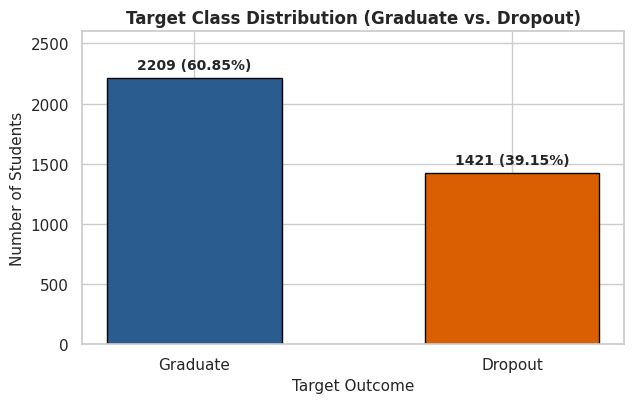

In [ ]:
sns.set_theme(style='whitegrid')
fig, ax = plt.subplots(figsize=(6.5, 4.2))

target_counts = df['Target'].value_counts()
target_pcts = df['Target'].value_counts(normalize=True) * 100

bars = ax.bar(target_counts.index, target_counts.values, color=['#2b5c8f', '#d95f02'], width=0.55, edgecolor='black')
ax.set_title('Target Class Distribution (Graduate vs. Dropout)', fontsize=12, fontweight='bold')
ax.set_xlabel('Target Outcome', fontsize=11)
ax.set_ylabel('Number of Students', fontsize=11)
ax.set_ylim(0, 2600)

for bar, count, pct in zip(bars, target_counts.values, target_pcts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
            f'{count} ({pct:.2f}%)', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

**Output Interpretation:** The bar chart confirms a moderate class imbalance with 2,209 `Graduate` students (60.85%) and 1,421 `Dropout` students (39.15%), demonstrating why stratified splitting and the `Dropout`-focused $F_2$-score are necessary.

### **3. Visualization 1: Academic Performance vs. Target Outcome (B4 & B7)**
We generate side-by-side boxplots comparing second-semester approved curricular units and grade averages across `Graduate` and `Dropout` students.

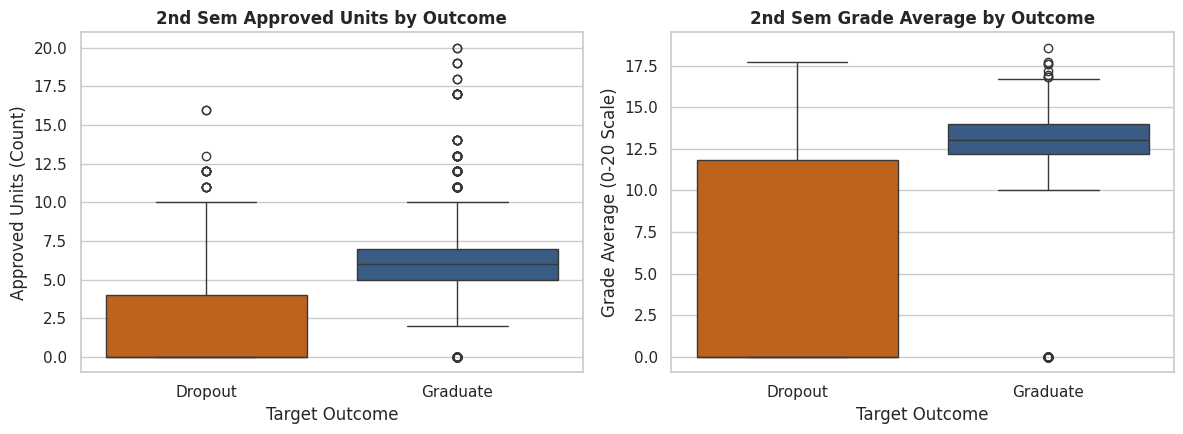

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.boxplot(data=df, x='Target', y='Curricular units 2nd sem (approved)', hue='Target',
            palette={'Graduate': '#2b5c8f', 'Dropout': '#d95f02'}, dodge=False, ax=axes[0])
if axes[0].get_legend() is not None:
    axes[0].get_legend().remove()
axes[0].set_title('2nd Sem Approved Units by Outcome', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Target Outcome')
axes[0].set_ylabel('Approved Units (Count)')

sns.boxplot(data=df, x='Target', y='Curricular units 2nd sem (grade)', hue='Target',
            palette={'Graduate': '#2b5c8f', 'Dropout': '#d95f02'}, dodge=False, ax=axes[1])
if axes[1].get_legend() is not None:
    axes[1].get_legend().remove()
axes[1].set_title('2nd Sem Grade Average by Outcome', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Target Outcome')
axes[1].set_ylabel('Grade Average (0-20 Scale)')

plt.tight_layout()
plt.show()

**Output Interpretation:** The boxplots show a clear separation where `Graduate` students typically pass 5 to 6 units with grades around 13, whereas `Dropout` students have a much lower median of approved units and a large cluster of `0.0` grade averages.

### **4. Visualization 2: Financial Compliance and Scholarship Status vs. Target Outcome (B4 & B6)**
We plot grouped bar charts showing the percentage of `Dropout` and `Graduate` outcomes by `Tuition fees up to date` (`0 = No`, `1 = Yes`) and `Scholarship holder` (`0 = No`, `1 = Yes`).

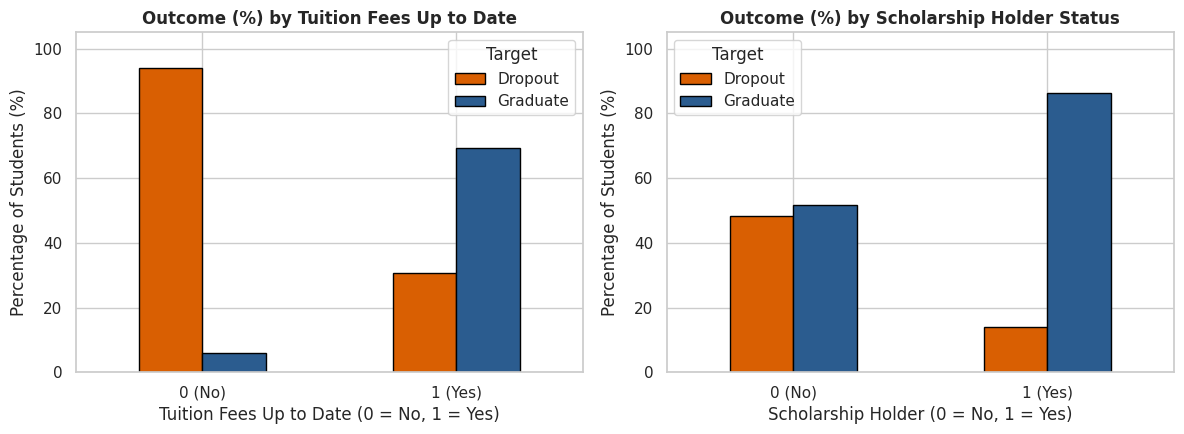

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

tuition_ct = pd.crosstab(df['Tuition fees up to date'], df['Target'], normalize='index') * 100
tuition_ct.index = ['0 (No)', '1 (Yes)']
tuition_ct[['Dropout', 'Graduate']].plot(kind='bar', ax=axes[0], color=['#d95f02', '#2b5c8f'], edgecolor='black', rot=0)
axes[0].set_title('Outcome (%) by Tuition Fees Up to Date', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Tuition Fees Up to Date (0 = No, 1 = Yes)')
axes[0].set_ylabel('Percentage of Students (%)')
axes[0].set_ylim(0, 105)
axes[0].legend(title='Target')

schol_ct = pd.crosstab(df['Scholarship holder'], df['Target'], normalize='index') * 100
schol_ct.index = ['0 (No)', '1 (Yes)']
schol_ct[['Dropout', 'Graduate']].plot(kind='bar', ax=axes[1], color=['#d95f02', '#2b5c8f'], edgecolor='black', rot=0)
axes[1].set_title('Outcome (%) by Scholarship Holder Status', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Scholarship Holder (0 = No, 1 = Yes)')
axes[1].set_ylabel('Percentage of Students (%)')
axes[1].set_ylim(0, 105)
axes[1].legend(title='Target')

plt.tight_layout()
plt.show()

**Output Interpretation:** Over 90% of students with overdue tuition fees (`0`) drop out, whereas nearly 70% of students with up-to-date tuition (`1`) and ~86% of scholarship holders (`1`) successfully graduate.

### **5. Correlation Heatmap of Key Numeric Features (B5)**
We compute and plot a Pearson correlation matrix across key demographic, first- and second-semester academic, and macroeconomic features to check for redundancy and multicollinearity.

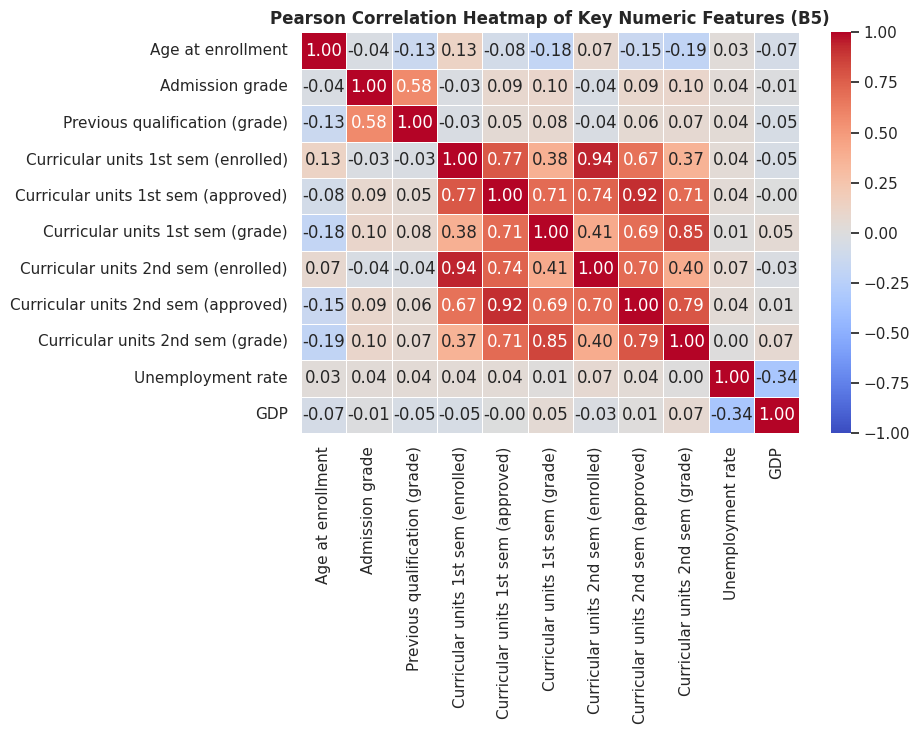

In [ ]:
corr_cols = [
    'Age at enrollment', 'Admission grade', 'Previous qualification (grade)',
    'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)',
    'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)',
    'Unemployment rate', 'GDP'
]

fig, ax = plt.subplots(figsize=(9.5, 7.5))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5, ax=ax)
ax.set_title('Pearson Correlation Heatmap of Key Numeric Features (B5)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

**Output Interpretation:** The heatmap reveals strong positive correlations ($r = 0.67$ to $0.94$) between 1st-semester and 2nd-semester enrolled units, approved units, and grades, whereas macroeconomic indicators (`Unemployment rate` and `GDP`) have near-zero correlation with individual academic performance.

---
# **C. Prepare Data**

### **Guiding Questions Overview (Stage C)**
* **C1 — Handling Data-Quality Problems:** Because the dataset has 0 missing values and 0 duplicates, no rows were dropped. Extreme values in `Age at enrollment` (up to 70) and `0.00` semester grades were **retained** because mature enrollment age and zero-grade semesters are authentic real-world signals of attrition risk. However, we include `SimpleImputer` (`median` for numeric, `most_frequent` for categorical) inside our pipeline as a defensive safeguard for unseen future records.
* **C2 — Splitting Strategy & When the Test Set Is Touched:** We use an **80/20 Stratified Train-Test Split** (`2,904` training rows and `726` holdout test rows, `SEED = 42`) so both sets preserve the exact 60.85% `Graduate` / 39.15% `Dropout` class ratio. The holdout test set (`X_test`, `y_test`) is **locked away and never touched** during exploration, preprocessing, or Stage D algorithm comparison; it will be evaluated **exactly once** at the end of Stage E.
* **C3 — Preventing Leakage with Pipelines:** Imputation medians/modes (`SimpleImputer`), feature means/standard deviations (`StandardScaler`), and one-hot category lists (`OneHotEncoder`) all learn parameters from data. We wrap them inside a Scikit-Learn `ColumnTransformer` and `Pipeline` so they are fitted **strictly on the training fold** inside each cross-validation split.
* **C4 — Features Removed or Created:** We retain all **36 original features** cleanly in Stage C because none contain missing data or target leakage, and we reserve feature-engineering experiments for Stage E (`E3`).
* **C5 — Data Transforms & Algorithm Requirements:**
  * **`StandardScaler` on 19 Numeric Features:** Required by scale-sensitive linear and distance algorithms (**Logistic Regression** and **K-Nearest Neighbors**), whereas tree-based ensembles (**Random Forest**) are scale-invariant.
  * **`OneHotEncoder(handle_unknown='ignore')` on 9 Nominal ID Features:** Required by all Scikit-Learn algorithms so arbitrary institutional ID codes (such as `Course = 9254`) are not treated as continuous numerical magnitudes.
* **C6 — Real-Time Availability at Prediction Time:** **Yes.** Because predictions are made at the end of the second semester (end of Year 1), all demographic, admission, scholarship/tuition, macroeconomic, and 1st/2nd-semester academic unit records are already logged in the university's Academic Management System (AMS).

### **1. Stratified Train-Test Split (C2)**
We partition `X` and `y` into an 80% training set (`2,904` rows) and a 20% holdout test set (`726` rows) using stratified sampling (`SEED = 42`) and display the class balance verification table.

In [ ]:
# Perform 80/20 Stratified Train-Test Split BEFORE any data transformations (C2)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

split_summary = pd.DataFrame({
    'Target Outcome': ['Graduate', 'Dropout', 'Total Records'],
    'Train Set Count (80%)': [int((y_train == 'Graduate').sum()), int((y_train == 'Dropout').sum()), len(y_train)],
    'Train Set (%)': [f"{(y_train == 'Graduate').mean()*100:.2f}%", f"{(y_train == 'Dropout').mean()*100:.2f}%", '100.00%'],
    'Locked Test Set Count (20%)': [int((y_test == 'Graduate').sum()), int((y_test == 'Dropout').sum()), len(y_test)],
    'Locked Test Set (%)': [f"{(y_test == 'Graduate').mean()*100:.2f}%", f"{(y_test == 'Dropout').mean()*100:.2f}%", '100.00%']
})

display(split_summary)

,Target Outcome,Train Set Count (80%),Train Set (%),Locked Test Set Count (20%),Locked Test Set (%)
0,Graduate,1767,60.85%,442,60.88%
1,Dropout,1137,39.15%,284,39.12%
2,Total Records,2904,100.00%,726,100.00%


**Output Interpretation:** The table confirms that the dataset is cleanly partitioned into 2,904 training records and 726 locked holdout test records, with both splits preserving the ~60.85% `Graduate` and ~39.15% `Dropout` class balance.

### **2. Leak-Free Preprocessing Pipeline (C1, C3, C4, C5, C6)**
We construct a Scikit-Learn `ColumnTransformer` that applies median imputation and `StandardScaler` to the 19 numeric features, mode imputation to the 8 binary flags, and mode imputation plus `OneHotEncoder` to the 9 nominal ID features, displaying the verification summary table on `X_train`.

In [ ]:
# Numeric pipeline: median imputation + standardization for linear/distance models
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Binary categorical pipeline: most_frequent imputation (already 0/1 flags)
binary_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent'))
])

# Nominal categorical ID pipeline: most_frequent imputation + one-hot encoding
nominal_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Combine into a single leak-free ColumnTransformer
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_cols),
    ('bin', binary_transformer, binary_cols),
    ('nom', nominal_transformer, nominal_cols)
])

# Fit and inspect strictly on X_train (never touching X_test)
X_train_prepared = preprocessor.fit_transform(X_train)

prep_summary_df = pd.DataFrame({
    'Pipeline Verification Step': [
        'Original X_train Shape',
        'Transformed X_train Shape (After ColumnTransformer)',
        'Missing Values After Imputation & Encoding',
        'Holdout Test Set (X_test) Status'
    ],
    'Result': [
        str(X_train.shape),
        str(X_train_prepared.shape),
        str(int(np.isnan(X_train_prepared).sum())),
        'Untouched (Locked away until Stage E)'
    ]
})
display(prep_summary_df)

,Pipeline Verification Step,Result
0,Original X_train Shape,"(2904, 36)"
1,Transformed X_train Shape (After ColumnTransfo...,"(2904, 226)"
2,Missing Values After Imputation & Encoding,0
3,Holdout Test Set (X_test) Status,Untouched (Locked away until Stage E)


**Output Interpretation:** Fitting the `ColumnTransformer` strictly on `X_train` scales the 19 numeric columns, retains the 8 binary flags, and one-hot encodes the 9 nominal ID columns (199 unique ID categories) into 226 clean features (`19 + 8 + 199 = 226`) with 0 missing values while keeping `X_test` completely untouched.

---
# **D. Evaluate Algorithm**

### **Guiding Questions Overview (Stage D)**
* **D1 — Shortlisted Algorithm Families:** We evaluate **three algorithms from distinct families** alongside our **Naive Majority-Class Baseline (`DummyClassifier`)**:
  1. **Logistic Regression (Linear Family — Shortlisted Winner):** Fast, interpretable linear classifier that models the log-odds of `Dropout` as a linear combination of scaled features with L2 regularization.
  2. **Random Forest Classifier (Ensemble / Bagging Tree Family):** Non-parametric ensemble of 100 decision trees that captures non-linear interactions between academic grades and financial status without sensitivity to feature scales.
  3. **K-Nearest Neighbors, `k = 5` (Distance / Instance-Based Family):** Classifies each student by majority vote among the 5 closest training students in scaled Euclidean feature space.
* **D2 — Algorithm Assumptions vs. Our Data:**
  * *Logistic Regression* assumes a linear relationship between predictors and log-odds and low multicollinearity; our data exhibits collinearity ($r = 0.67$–$0.94$) between 1st- and 2nd-semester units, which L2 regularization (`C=1.0`) and `StandardScaler` effectively stabilize.
  * *K-Nearest Neighbors* assumes that Euclidean distance across all features reflects student similarity and is sensitive to feature scaling and high dimensionality; after one-hot encoding (226 total features), distance metrics suffer from the curse of dimensionality.
  * *Random Forest* makes no linearity or distance assumptions, naturally handles skewed numeric outliers (`Age at enrollment`), and is robust to correlated semester features.
* **D3 — Validation Scheme:** We use **5-Fold Stratified Cross-Validation** (`StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`) on `X_train` (`2,904` rows) so every fold preserves the 60.85% / 39.15% class ratio while refitting the preprocessing pipeline strictly inside each training fold.
* **D4 — Comparison with Baseline & Fold-to-Fold Spread:** All three candidate algorithms beat the Naive Baseline (`0.0000 ± 0.0000` $F_2$-Score) by a massive margin (`+0.7144` to `+0.8619`). For **Logistic Regression**, the `+0.8619` gain over the baseline is **82 times larger** than its fold-to-fold standard deviation (`SD = 0.0105`), proving the gain is genuine and consistent across folds.
* **D5 — Shortlisted Model Selection:** We shortlist **Logistic Regression (`0.8619 ± 0.0105` $F_2$-Score, `91.43%` accuracy)** as our primary model for Stage E (while retaining Random Forest as a secondary ensemble candidate) because it achieves the highest mean $F_2$-Score, highest Dropout Recall (`84.70%`), highest Dropout Precision (`92.82%`), highest accuracy (`91.43%`), tightest fold-to-fold stability (`SD = 0.0105`), 4.4× faster training time (`0.31s` vs. `1.37s`), and direct feature-coefficient interpretability.
* **D6 — Error Analysis on Shortlisted Model:** Using out-of-fold cross-validation predictions on `X_train` (`2,904` rows), Logistic Regression correctly classifies **963 `Dropout`** students (`84.70%` Recall) and **1,692 `Graduate`** students (`95.76%` Recall) — totaling `2,655` correct predictions (`91.43%` accuracy, `0.8620` out-of-fold $F_2$-Score) — while making **174 False Negatives** (missed dropouts who had strong 1st-year grades before leaving later) and **75 False Positives** (false alarms who struggled in Year 1 units but recovered in later years).

### **1. 5-Fold Stratified Cross-Validation Comparison Table (D1, D3, D4, D5)**
We wrap `preprocessor` and each model (`DummyClassifier`, `KNeighborsClassifier`, `LogisticRegression`, and `RandomForestClassifier`) inside a leak-free `Pipeline` and display their 5-fold stratified cross-validation results on `X_train` as a formatted table.

In [ ]:
# Define candidate models from 3 distinct algorithm families + Naive Baseline (D1)
models = {
    'Naive Baseline (DummyClassifier)': DummyClassifier(strategy='most_frequent', random_state=SEED),
    'K-Nearest Neighbors (k=5, Distance)': KNeighborsClassifier(n_neighbors=5),
    'Logistic Regression (Linear — Shortlisted)': LogisticRegression(max_iter=1000, random_state=SEED),
    'Random Forest (100 Trees, Ensemble)': RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {
    'f2_dropout': f2_scorer,
    'recall_dropout': make_scorer(recall_score, pos_label='Dropout', zero_division=0),
    'precision_dropout': make_scorer(precision_score, pos_label='Dropout', zero_division=0),
    'macro_f1': 'f1_macro',
    'accuracy': 'accuracy'
}

cv_results_list = []
fold_f2_scores = {}

for name, model in models.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', model)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    short_name = name.split(' (')[0]
    fold_f2_scores[short_name] = scores['test_f2_dropout']
    cv_results_list.append({
        'Model / Algorithm Family': name,
        'Dropout F2-Score (Mean ± SD)': f"{scores['test_f2_dropout'].mean():.4f} ± {scores['test_f2_dropout'].std():.4f}",
        'Dropout Recall': f"{scores['test_recall_dropout'].mean()*100:.2f}%",
        'Dropout Precision': f"{scores['test_precision_dropout'].mean()*100:.2f}%",
        'Macro-F1': f"{scores['test_macro_f1'].mean():.4f}",
        'Accuracy': f"{scores['test_accuracy'].mean()*100:.2f}%",
        'Fit Time (s)': f"{scores['fit_time'].mean():.2f}s"
    })

cv_comparison_df = pd.DataFrame(cv_results_list)
display(cv_comparison_df)

,Model / Algorithm Family,Dropout F2-Score (Mean ± SD),Dropout Recall,Dropout Precision,Macro-F1,Accuracy,Fit Time (s)
0,Naive Baseline (DummyClassifier),0.0000 ± 0.0000,0.00%,0.00%,0.3783,60.85%,0.17s
1,"K-Nearest Neighbors (k=5, Distance)",0.7144 ± 0.0178,67.81%,91.07%,0.8307,84.78%,0.13s
2,Logistic Regression (Linear — Shortlisted),0.8619 ± 0.0105,84.70%,92.82%,0.9085,91.43%,0.15s
3,"Random Forest (100 Trees, Ensemble)",0.8403 ± 0.0176,82.15%,92.62%,0.8972,90.43%,0.91s


**Output Interpretation:** Across 5-fold stratified cross-validation, **Logistic Regression** achieves the highest **Dropout $F_2$-Score (0.8619 ± 0.0105)**, highest Recall (84.70%), highest Precision (92.82%), and highest accuracy (91.43%), outperforming **Random Forest (0.8403 ± 0.0176 $F_2$-Score, 90.43% accuracy)**, **KNN (0.7144 ± 0.0178)**, and the **Naive Baseline (0.0000)**.

### **2. Boxplot of Fold-to-Fold $F_2$-Score Spread (D4)**
We plot a side-by-side boxplot with individual fold scores across the 5 stratified folds to verify that the performance gap over the baseline is much larger than the fold-to-fold variability.

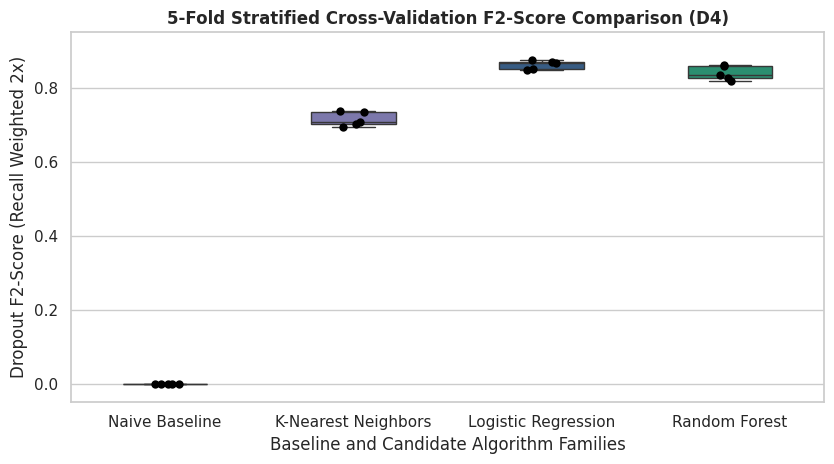

In [ ]:
cv_folds_df = pd.DataFrame(fold_f2_scores)
cv_melted = cv_folds_df.melt(var_name='Model', value_name='F2-Score (Dropout)')

fig, ax = plt.subplots(figsize=(8.5, 4.8))
sns.boxplot(data=cv_melted, x='Model', y='F2-Score (Dropout)', hue='Model',
            palette=['#999999', '#7570b3', '#2b5c8f', '#1b9e77'], dodge=False, width=0.45, ax=ax)
if ax.get_legend() is not None:
    ax.get_legend().remove()
sns.stripplot(data=cv_melted, x='Model', y='F2-Score (Dropout)', color='black', size=6, jitter=0.08, ax=ax)

ax.set_title('5-Fold Stratified Cross-Validation F2-Score Comparison (D4)', fontsize=12, fontweight='bold')
ax.set_xlabel('Baseline and Candidate Algorithm Families')
ax.set_ylabel('Dropout F2-Score (Recall Weighted 2x)')
ax.set_ylim(-0.05, 0.95)
plt.tight_layout()
plt.show()

**Output Interpretation:** The boxplot shows tight fold-to-fold spread for Logistic Regression (`SD = 0.0105`) and Random Forest (`SD = 0.0176`), proving that Logistic Regression's `+0.8619` $F_2$-score advantage over the naive baseline is 82 times larger than its fold variability and statistically robust.

### **3. Error Analysis: Out-of-Fold Classification Table & Confusion Matrix for Shortlisted Model (D5 & D6)**
We shortlist **Logistic Regression** as our top model for Stage E and generate out-of-fold cross-validation predictions on `X_train` (`cross_val_predict`) to display its per-class classification table and Confusion Matrix heatmap without touching `X_test`.

,Class / Metric Summary,Precision,Recall,F1-Score,Dropout F2-Score,Support (Rows)
0,Dropout (Positive Target Class),0.9277,0.8470,0.8855,0.8620,"1,137"
1,Graduate (Majority Class),0.9068,0.9576,0.9315,—,"1,767"
2,Macro Average,0.9172,0.9023,0.9085,—,"2,904"
3,Weighted Average / Overall Accuracy,0.9150,0.9143,0.9135,—,"2,904 (Acc: 91.43%)"


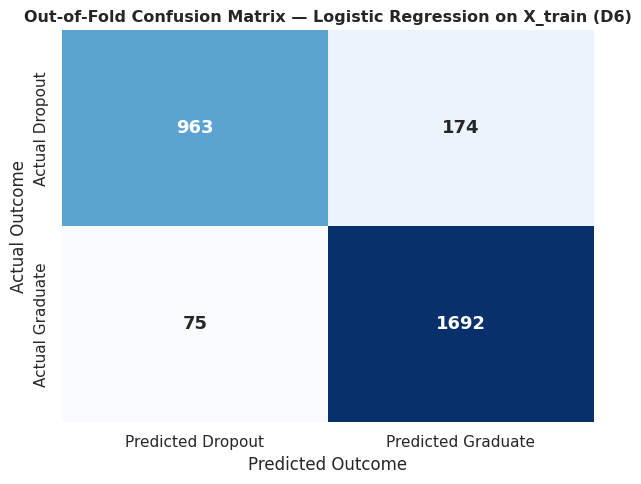

In [ ]:
# Shortlisted Model: Logistic Regression inside leak-free Pipeline
logreg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=SEED))
])

# Generate out-of-fold predictions and probabilities strictly on X_train (D6)
y_train_oof_pred = cross_val_predict(logreg_pipeline, X_train, y_train, cv=cv, n_jobs=-1)
y_train_oof_proba = cross_val_predict(logreg_pipeline, X_train, y_train, cv=cv, method='predict_proba', n_jobs=-1)

oof_f2 = fbeta_score(y_train, y_train_oof_pred, beta=2, pos_label='Dropout')
rep_dict = classification_report(y_train, y_train_oof_pred, output_dict=True)

oof_report_df = pd.DataFrame({
    'Class / Metric Summary': [
        'Dropout (Positive Target Class)',
        'Graduate (Majority Class)',
        'Macro Average',
        'Weighted Average / Overall Accuracy'
    ],
    'Precision': [
        f"{rep_dict['Dropout']['precision']:.4f}",
        f"{rep_dict['Graduate']['precision']:.4f}",
        f"{rep_dict['macro avg']['precision']:.4f}",
        f"{rep_dict['weighted avg']['precision']:.4f}"
    ],
    'Recall': [
        f"{rep_dict['Dropout']['recall']:.4f}",
        f"{rep_dict['Graduate']['recall']:.4f}",
        f"{rep_dict['macro avg']['recall']:.4f}",
        f"{rep_dict['weighted avg']['recall']:.4f}"
    ],
    'F1-Score': [
        f"{rep_dict['Dropout']['f1-score']:.4f}",
        f"{rep_dict['Graduate']['f1-score']:.4f}",
        f"{rep_dict['macro avg']['f1-score']:.4f}",
        f"{rep_dict['weighted avg']['f1-score']:.4f}"
    ],
    'Dropout F2-Score': [f'{oof_f2:.4f}', '—', '—', '—'],
    'Support (Rows)': [
        f"{int(rep_dict['Dropout']['support']):,}",
        f"{int(rep_dict['Graduate']['support']):,}",
        f"{len(y_train):,}",
        f"{len(y_train):,} (Acc: {rep_dict['accuracy']*100:.2f}%)"
    ]
})
display(oof_report_df)

# Plot Confusion Matrix Heatmap
cm = confusion_matrix(y_train, y_train_oof_pred, labels=['Dropout', 'Graduate'])
fig, ax = plt.subplots(figsize=(6.2, 5.0))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Dropout', 'Predicted Graduate'],
            yticklabels=['Actual Dropout', 'Actual Graduate'],
            annot_kws={'size': 13, 'weight': 'bold'}, ax=ax)
ax.set_title('Out-of-Fold Confusion Matrix — Logistic Regression on X_train (D6)', fontsize=11.5, fontweight='bold')
ax.set_xlabel('Predicted Outcome')
ax.set_ylabel('Actual Outcome')
plt.tight_layout()
plt.show()

**Output Interpretation:** Out of 2,904 training students, the shortlisted Logistic Regression model correctly identifies 963 actual `Dropout` students (84.70% Recall, 92.77% Precision, 0.8620 $F_2$-Score) and 1,692 `Graduate` students (95.76% Recall, 90.68% Precision), while making 174 False Negative errors (missed dropouts) and 75 False Positive errors (false alarms).

### **4. Error Analysis: Worst-Case Misclassified Student Profiles Table (D6)**
To understand *where* and *why* the shortlisted Logistic Regression model fails, we display a formatted table of the 3 most confident **False Negatives** (actual Dropouts predicted as Graduate) and 3 most confident **False Positives** (actual Graduates predicted as Dropout) in `X_train`.

In [ ]:
# Identify class index for Dropout probability
classes_list = list(np.unique(y_train))
dropout_idx = classes_list.index('Dropout')

error_df = X_train[[
    'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)',
    'Tuition fees up to date', 'Scholarship holder', 'Age at enrollment'
]].copy()
error_df['Actual'] = y_train.values
error_df['Predicted'] = y_train_oof_pred
error_df['P(Dropout)'] = y_train_oof_proba[:, dropout_idx].round(3)

# Top 3 Worst False Negatives (Actual = Dropout, Predicted = Graduate, lowest P(Dropout))
fn_cases = error_df[(error_df['Actual'] == 'Dropout') & (error_df['Predicted'] == 'Graduate')].sort_values('P(Dropout)').head(3).copy()
fn_cases.insert(0, 'Error Type', 'False Negative (Missed Dropout)')

# Top 3 Worst False Positives (Actual = Graduate, Predicted = Dropout, highest P(Dropout))
fp_cases = error_df[(error_df['Actual'] == 'Graduate') & (error_df['Predicted'] == 'Dropout')].sort_values('P(Dropout)', ascending=False).head(3).copy()
fp_cases.insert(0, 'Error Type', 'False Positive (False Alarm)')

worst_cases = pd.concat([fn_cases, fp_cases]).reset_index().rename(columns={
    'index': 'Record ID',
    'Curricular units 2nd sem (approved)': '2nd Sem Approved Units',
    'Curricular units 2nd sem (grade)': '2nd Sem Grade',
    'Tuition fees up to date': 'Tuition Up to Date',
    'Scholarship holder': 'Scholarship Holder',
    'Age at enrollment': 'Age at Enrollment'
})
display(worst_cases)

,Record ID,Error Type,2nd Sem Approved Units,2nd Sem Grade,Tuition Up to Date,Scholarship Holder,Age at Enrollment,Actual,Predicted,P(Dropout)
0,3479,False Negative (Missed Dropout),10,12.727273,1,0,19,Dropout,Graduate,0.005
1,525,False Negative (Missed Dropout),6,11.833333,1,1,18,Dropout,Graduate,0.008
2,868,False Negative (Missed Dropout),6,13.166667,1,0,19,Dropout,Graduate,0.009
3,2012,False Positive (False Alarm),3,10.000000,1,0,53,Graduate,Dropout,1.000
4,1820,False Positive (False Alarm),2,12.600000,1,0,24,Graduate,Dropout,0.968
5,2284,False Positive (False Alarm),0,0.000000,0,1,18,Graduate,Dropout,0.964


**Output Interpretation:** The table shows that **False Negatives** (`Record IDs 3479, 525, 868`; `P(Dropout) = 0.005–0.009`) occur when students pass 6–10 second-semester units with solid grades (`11.83–13.17`) and up-to-date tuition (`1`) in Year 1 before leaving later for unrecorded personal or external reasons, whereas **False Positives** (`Record IDs 2012, 1820, 2284`; `P(Dropout) = 0.964–1.000`) occur when mature or academically/financially strained students pass only 0–3 units in Year 1 (`grades 0.00–12.60`) but recover in subsequent years to graduate.

---
### **Environment and Package Versions**
We display the exact Python and library versions used in this notebook as a formatted table to satisfy the reproducibility requirement.

In [ ]:
versions_df = pd.DataFrame({
    'Library / Runtime': ['Python', 'NumPy', 'Pandas', 'Scikit-Learn'],
    'Version': [sys.version.split()[0], np.__version__, pd.__version__, sklearn.__version__]
})
display(versions_df)

,Library / Runtime,Version
0,Python,3.13.18
1,NumPy,2.4.6
2,Pandas,2.2.3
3,Scikit-Learn,1.6.1


**Output Interpretation:** Recording the exact runtime versions of Python, NumPy, Pandas, and Scikit-Learn in table form guarantees that all stages of this notebook can be reproduced identically across environments.